# CompFlow demo: from two frames to a dense motion map

This notebook illustrates how the public **CompFlow** repository (https://github.com/migueldiaz1/CompFlow) works, end to end, on a `SynthCells` sample pair:

1. load a frame pair from the repo's bundled sample data,
2. look at it -- full cell, then three 30x30 zoomed regions,
3. run `CompFlow-Patch` (the method proposed in the paper) on it to get a dense motion map,
4. plot that motion map -- full cell as a dense per-pixel direction map, zoom as colored quiver arrows (same style as `Results/figura_potencial_metodo/K=3/figura_potencial_metodo_celula1_K3_p123_salto40.png`),
5. **cross-check**: run the exact same pair through the original (`paper 1/main`) implementation and confirm the two give the same result.

Runs in a dedicated virtual environment (`venv/`, kernel "CompFlow Demo", created by `setup.sh`) against this repository's own CompFlow code, which lives right alongside this notebook (`CompFlow/`, `Comparison_methods/`, `inference.py`, etc. -- a snapshot taken when this notebook was written, not the working copy used elsewhere in this project, so this reflects exactly what an external user cloning this repo today would get).

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import torch

REPO = os.getcwd()          # this repo's own root (CompFlow code + notebook live side by side here)
sys.path.insert(0, REPO)
sys.path.insert(0, os.path.join(REPO, "Datasets"))
sys.path.insert(0, os.path.join(REPO, "Metrics"))

from inference import estimate_flow          # repo's public API
from load_sample import load_pair, n_pairs   # repo's sample-data loader

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

/home/migueldi/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


torch 2.5.1+cu121 | cuda available: True


## 1. Load a SynthCells sample pair

`Datasets/SynthCells_sample.zip` ships 30 pairs with dense ground truth (not needed here, just the frames).

In [2]:
ZIP_PATH = os.path.join(REPO, "Datasets", "SynthCells_sample.zip")

rng_pair = np.random.default_rng()         # unseeded: a different pair every run
PAIR_IDX = int(rng_pair.integers(0, n_pairs(ZIP_PATH)))

print(f"{n_pairs(ZIP_PATH)} pairs available in {os.path.basename(ZIP_PATH)} -- using random pair #{PAIR_IDX}")
img1, img2, gt = load_pair(ZIP_PATH, PAIR_IDX)
mask = gt["mask"]
print(f"frame shape: {img1.shape}, dtype: {img1.dtype}")

30 pairs available in SynthCells_sample.zip -- using random pair #18
frame shape: (256, 256), dtype: uint8


## 2. Full cell, then three 30x30 zoomed regions

Three interior points of the cell mask, spread apart, each giving a 30x30 crop.

In [3]:
ZOOM = 30
ZOOM_COLORS = ["#e6194b", "#3cb44b", "#4363d8"]


def pick_zoom_regions(mask, size=30, n=3, seed=None, min_sep=40):
    """n interior (y0, x0) top-left corners, size x size, fully inside the
    mask's bounding box and spread at least min_sep apart from each other.
    seed=None (default) -> a different, genuinely random set each run."""
    ys, xs = np.nonzero(mask > 0)
    y0, y1, x0, x1 = ys.min(), ys.max() - size, xs.min(), xs.max() - size
    rng = np.random.default_rng(seed)
    picks = []
    for _ in range(2000):
        cy, cx = rng.integers(y0, y1), rng.integers(x0, x1)
        if mask[cy + size // 2, cx + size // 2] == 0:
            continue
        if all(abs(cy - py) + abs(cx - px) > min_sep for py, px in picks):
            picks.append((cy, cx))
        if len(picks) == n:
            break
    return picks


zoom_regions = pick_zoom_regions(mask, size=ZOOM, n=3, seed=None)
print("zoom regions (y0, x0):", zoom_regions)

zoom regions (y0, x0): [(np.int64(176), np.int64(161)), (np.int64(194), np.int64(132)), (np.int64(81), np.int64(141))]


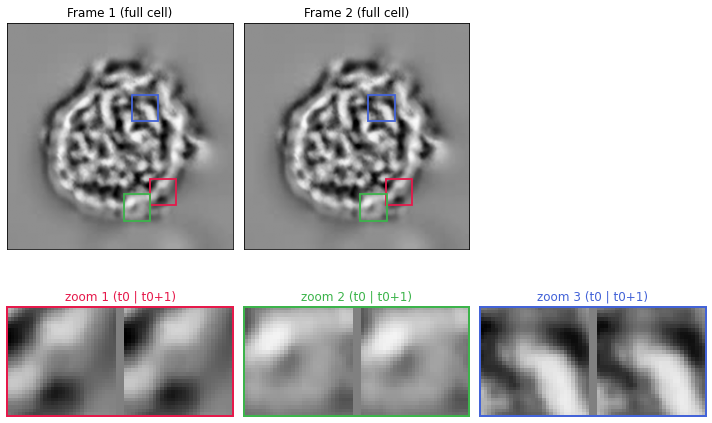

In [4]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, img, title in ((axes[0, 0], img1, "Frame 1 (full cell)"), (axes[0, 1], img2, "Frame 2 (full cell)")):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    for (y0, x0), color in zip(zoom_regions, ZOOM_COLORS):
        ax.add_patch(Rectangle((x0, y0), ZOOM, ZOOM, fill=False, edgecolor=color, linewidth=1.8))
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 2].axis("off")

for i, ((y0, x0), color) in enumerate(zip(zoom_regions, ZOOM_COLORS)):
    sl = (slice(y0, y0 + ZOOM), slice(x0, x0 + ZOOM))
    crop = np.concatenate([img1[sl], np.full((ZOOM, 2), 128, dtype=np.uint8), img2[sl]], axis=1)
    ax = axes[1, i]
    ax.imshow(crop, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"zoom {i+1} (t0 | t0+1)", color=color)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_edgecolor(color); sp.set_linewidth(2)

fig.tight_layout()
plt.show()

## 3. Dense motion map with CompFlow-Patch (from the GitHub repo)

`dataset="SynthCells"` pulls the exact SynthCells-calibrated parameters the paper uses for this method (`CompFlow/configs/dataset_params.json`) -- no parameters to set by hand.

In [5]:
torch.manual_seed(0)
u_gh, v_gh = estimate_flow(img1, img2, method="CompFlow-Patch", dataset="SynthCells", device=DEVICE)

print(f"u: shape={u_gh.shape}  mean={u_gh.mean():.4f}")
print(f"v: shape={v_gh.shape}  mean={v_gh.mean():.4f}")
print(f"|w| mean (inside mask) = {np.hypot(u_gh, v_gh)[mask > 0].mean():.4f} px/frame")

u: shape=(256, 256)  mean=0.0000
v: shape=(256, 256)  mean=0.0004
|w| mean (inside mask) = 0.0862 px/frame


## 4. Plotting the dense motion map

Same visual convention as `Results/figura_potencial_metodo/` throughout the paper: **full cell = a fully dense per-pixel direction map** (every pixel gets a color, no arrows -- arrows that dense would just be a solid block); **zoom = actual colored quiver arrows** (hue = direction, same HSV colormap as the dense map, thickness tiered by magnitude, staggered grid so the spacing looks even). SynthCells ships dense per-pixel ground truth, so the direction and magnitude columns are each shown **twice, side by side: `CompFlow-Patch` (estimated) vs. ground truth** -- 7 columns in total, the same first 5 of `figura_potencial_metodo_celula1_K3_p123_salto40.png` plus the GT pair.

In [6]:
from matplotlib.colors import hsv_to_rgb, ListedColormap, Normalize


def density_from_img(img):
    """Chromatin density from intensity: dark = dense (dark_is_dense=True,
    the convention used for SynthCells/RealCells throughout the paper)."""
    return 1.0 - img.astype(np.float32) / 255.0


def color_by_diff(diff, base, amplitude=0.5, smoothness=0.16):
    """diff>0 (gained density) -> green; diff<0 (lost density) -> red.
    tanh instead of a hard threshold: small frame-to-frame noise stays
    visible but faint rather than being clipped to exactly zero."""
    s = amplitude * np.tanh(diff / smoothness)
    mag = np.abs(s)
    R = np.clip(base - s, 0, 1)
    G = np.clip(base + s, 0, 1)
    B = np.clip(base - mag, 0, 1)
    return R, G, B


def overlay_lost_gained(img1, img2, mask):
    d1, d2 = density_from_img(img1), density_from_img(img2)
    diff = d2 - d1
    # background shading = raw intensity, NOT density -- so a dense (dark)
    # region stays dark here too, exactly like it looks in the Frame 1/2
    # panels. Using density for the background instead would make dense
    # (dark) regions render white, which is backwards.
    base = (img1.astype(np.float32) / 255.0 + img2.astype(np.float32) / 255.0) / 2.0
    R, G, B = color_by_diff(diff, base)
    rgb = np.stack([R, G, B], axis=-1)
    rgb *= (mask > 0)[..., None]
    vmax_diff = float(np.percentile(np.abs(diff[mask > 0]), 99))
    return rgb, vmax_diff


def overlay_colormap(vmax_diff, n=256):
    diff = np.linspace(-vmax_diff, vmax_diff, n)
    R, G, B = color_by_diff(diff, base=0.5)
    return ListedColormap(np.stack([R, G, B], axis=-1))


def dense_direction_map(u, v, mask, img_bg, threshold=0.0):
    """Fully dense (every mask pixel above `threshold`, 0 = truly every
    pixel) per-pixel direction color, overlaid on the grayscale frame."""
    magnitude = np.hypot(u, v)
    angle = np.degrees(np.arctan2(v, u)) % 360.0
    hue = angle / 360.0
    hsv = np.stack([hue, np.ones_like(hue), np.ones_like(hue)], axis=-1)
    rgb = hsv_to_rgb(hsv)
    visible = (magnitude >= threshold) & (mask > 0)
    return rgb, visible


def colored_quiver(ax, u, v, mask, y0, x0, size, step=2.0, scale=30.0, width=0.0032, n_thickness=3):
    """Arrows colored by direction (hue, same HSV convention as the dense
    map), thickness tiered by magnitude, on a staggered (tresbolillo) grid
    of the given step so arrow spacing looks even instead of blocky."""
    ys1 = np.arange(y0 + step / 2.0, y0 + size, step)
    xs1 = np.arange(x0 + step / 2.0, x0 + size, step)
    Y1, X1 = np.meshgrid(ys1, xs1, indexing="ij")
    Y2, X2 = Y1 + step / 2.0, X1 + step / 2.0
    YY = np.round(np.concatenate([Y1.ravel(), Y2.ravel()])).astype(int)
    XX = np.round(np.concatenate([X1.ravel(), X2.ravel()])).astype(int)
    inside = (YY >= y0) & (YY < y0 + size) & (XX >= x0) & (XX < x0 + size)
    YY, XX = YY[inside], XX[inside]
    uu, vv = u[YY, XX], v[YY, XX]
    visible = mask[YY, XX] > 0
    uu, vv, YY, XX = uu[visible], vv[visible], YY[visible], XX[visible]
    mag = np.hypot(uu, vv)
    angle = np.degrees(np.arctan2(vv, uu)) % 360.0

    cuts = np.quantile(mag, np.linspace(0, 1, n_thickness + 1)) if mag.size else [0, 0]
    for i in range(n_thickness):
        lo, hi = cuts[i], cuts[i + 1]
        sel = (mag >= lo) & (mag <= hi if i == n_thickness - 1 else mag < hi)
        if not np.any(sel):
            continue
        factor = 1.0 + 0.4 * i
        ax.quiver(XX[sel], YY[sel], uu[sel] * scale, vv[sel] * scale, angle[sel],
                  cmap="hsv", norm=Normalize(0, 360), angles="xy", scale_units="xy", scale=1,
                  width=width * factor, headwidth=2.8 + 0.3 * i, headlength=3.4, headaxislength=3.0, pivot="mid")


def plot_motion_map_with_gt(img1, img2, mask, u_est, v_est, u_gt, v_gt,
                            zoom_regions, zoom_colors, zoom_size, suptitle=""):
    """Full breakdown, estimated vs. ground truth side by side: Frame 1,
    Frame 2, density lost/gained, flow direction (CompFlow-Patch | GT),
    |w| (CompFlow-Patch | GT) -- 7 columns. Full-cell row = dense per-pixel
    maps (no arrows); one row per zoom region = colored quiver arrows,
    same HSV-direction convention throughout. Direction/magnitude GT
    columns share their colorbar scale with their estimated counterpart
    so the two are directly comparable."""
    overlay_rgb, vmax_diff = overlay_lost_gained(img1, img2, mask)

    dense_rgb, dense_vis = dense_direction_map(u_est, v_est, mask, img1, threshold=0.0)
    dense_rgb_gt, dense_vis_gt = dense_direction_map(u_gt, v_gt, mask, img1, threshold=0.0)

    mag = np.where(mask > 0, np.hypot(u_est, v_est), np.nan)
    mag_gt = np.where(mask > 0, np.hypot(u_gt, v_gt), np.nan)
    vmax_mag = float(np.nanmax([np.nanpercentile(mag, 99), np.nanpercentile(mag_gt, 99)]))

    titles = ["Frame 1\n(chromatin density)", "Frame 2\n(chromatin density)",
             "Density\nlost / gained", "Flow direction\n(CompFlow-Patch)",
             "Flow direction\n(ground truth)", "$|\\mathbf{w}|$ (px/frame)\n(CompFlow-Patch)",
             "$|\\mathbf{w}|$ (px/frame)\n(ground truth)"]
    NCOL = 7
    N_ZOOM = len(zoom_regions)
    NROW = 1 + N_ZOOM

    fig = plt.figure(figsize=(NCOL * 4.2, 5.1 * NROW + 0.4))
    gs = fig.add_gridspec(NROW + 1, NCOL, height_ratios=[1] * NROW + [0.09], hspace=0.2, wspace=0.22,
                          top=0.95, bottom=0.015, left=0.02, right=0.98)
    axF = [fig.add_subplot(gs[0, j]) for j in range(NCOL)]
    axZ = [[fig.add_subplot(gs[1 + i, j]) for j in range(NCOL)] for i in range(N_ZOOM)]
    axC = [fig.add_subplot(gs[NROW, j]) for j in range(NCOL)]

    # ---- full-cell row -----------------------------------------------------
    axF[0].imshow(img1, cmap="gray", vmin=0, vmax=255)
    axF[1].imshow(img2, cmap="gray", vmin=0, vmax=255)
    axF[2].imshow(overlay_rgb)
    for j, (rgb, vis) in ((3, (dense_rgb, dense_vis)), (4, (dense_rgb_gt, dense_vis_gt))):
        axF[j].imshow(img1, cmap="gray", vmin=0, vmax=255)
        axF[j].imshow(np.concatenate([rgb, vis[..., None].astype(np.float32)], axis=-1))
    axF[5].imshow(mag, cmap="plasma", vmin=0, vmax=vmax_mag)
    axF[6].imshow(mag_gt, cmap="plasma", vmin=0, vmax=vmax_mag)

    for ax, title in zip(axF, titles):
        ax.set_title(title, fontsize=12, fontweight="bold")
        for (y0, x0), color in zip(zoom_regions, zoom_colors):
            ax.add_patch(Rectangle((x0, y0), zoom_size, zoom_size, fill=False, edgecolor=color, linewidth=1.6))

    # ---- one row per zoom region --------------------------------------------
    for i, (y0, x0) in enumerate(zoom_regions):
        color = zoom_colors[i]
        ext = (x0 - 0.5, x0 + zoom_size - 0.5, y0 + zoom_size - 0.5, y0 - 0.5)
        sl = (slice(y0, y0 + zoom_size), slice(x0, x0 + zoom_size))
        ax = axZ[i]

        ax[0].imshow(img1[sl], cmap="gray", vmin=0, vmax=255, extent=ext)
        ax[1].imshow(img2[sl], cmap="gray", vmin=0, vmax=255, extent=ext)
        ax[2].imshow(overlay_rgb[sl], extent=ext)
        ax[3].imshow(img1[sl], cmap="gray", vmin=0, vmax=255, extent=ext)
        colored_quiver(ax[3], u_est, v_est, mask, y0, x0, zoom_size, step=2.0, scale=30.0, width=0.0032)
        ax[4].imshow(img1[sl], cmap="gray", vmin=0, vmax=255, extent=ext)
        colored_quiver(ax[4], u_gt, v_gt, mask, y0, x0, zoom_size, step=2.0, scale=30.0, width=0.0032)
        ax[5].imshow(mag[sl], cmap="plasma", vmin=0, vmax=vmax_mag, extent=ext)
        ax[6].imshow(mag_gt[sl], cmap="plasma", vmin=0, vmax=vmax_mag, extent=ext)

        ax[0].set_ylabel(f"zoom {i+1}", fontsize=12, fontweight="bold", color=color)
        for a in ax:
            a.set_xlim(ext[0], ext[1]); a.set_ylim(ext[2], ext[3])
            for sp in a.spines.values():
                sp.set_edgecolor(color); sp.set_linewidth(1.8)

    # ---- shared colorbars ----------------------------------------------------
    for j in (0, 1):
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 255), cmap="gray_r"),
                          cax=axC[j], orientation="horizontal")
        cb.set_ticks([0, 255]); cb.set_ticklabels(["low", "high"])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-vmax_diff, vmax_diff), cmap=overlay_colormap(vmax_diff)),
                      cax=axC[2], orientation="horizontal")
    cb.set_ticks([-vmax_diff, 0, vmax_diff]); cb.ax.set_xticklabels([f"-{vmax_diff:.2f}\n(lost)", "0", f"{vmax_diff:.2f}\n(gained)"])
    for j in (3, 4):
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 360), cmap="hsv"),
                          cax=axC[j], orientation="horizontal", ticks=[0, 90, 180, 270, 360])
    for j in (5, 6):
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, vmax_mag), cmap="plasma"),
                          cax=axC[j], orientation="horizontal")
        cb.set_ticks([0, vmax_mag])

    for ax in [axF] + axZ:
        for a in ax:
            a.set_facecolor("black")
            a.set_xticks([]); a.set_yticks([])

    fig.suptitle(suptitle, fontsize=14, y=0.995)
    plt.show()

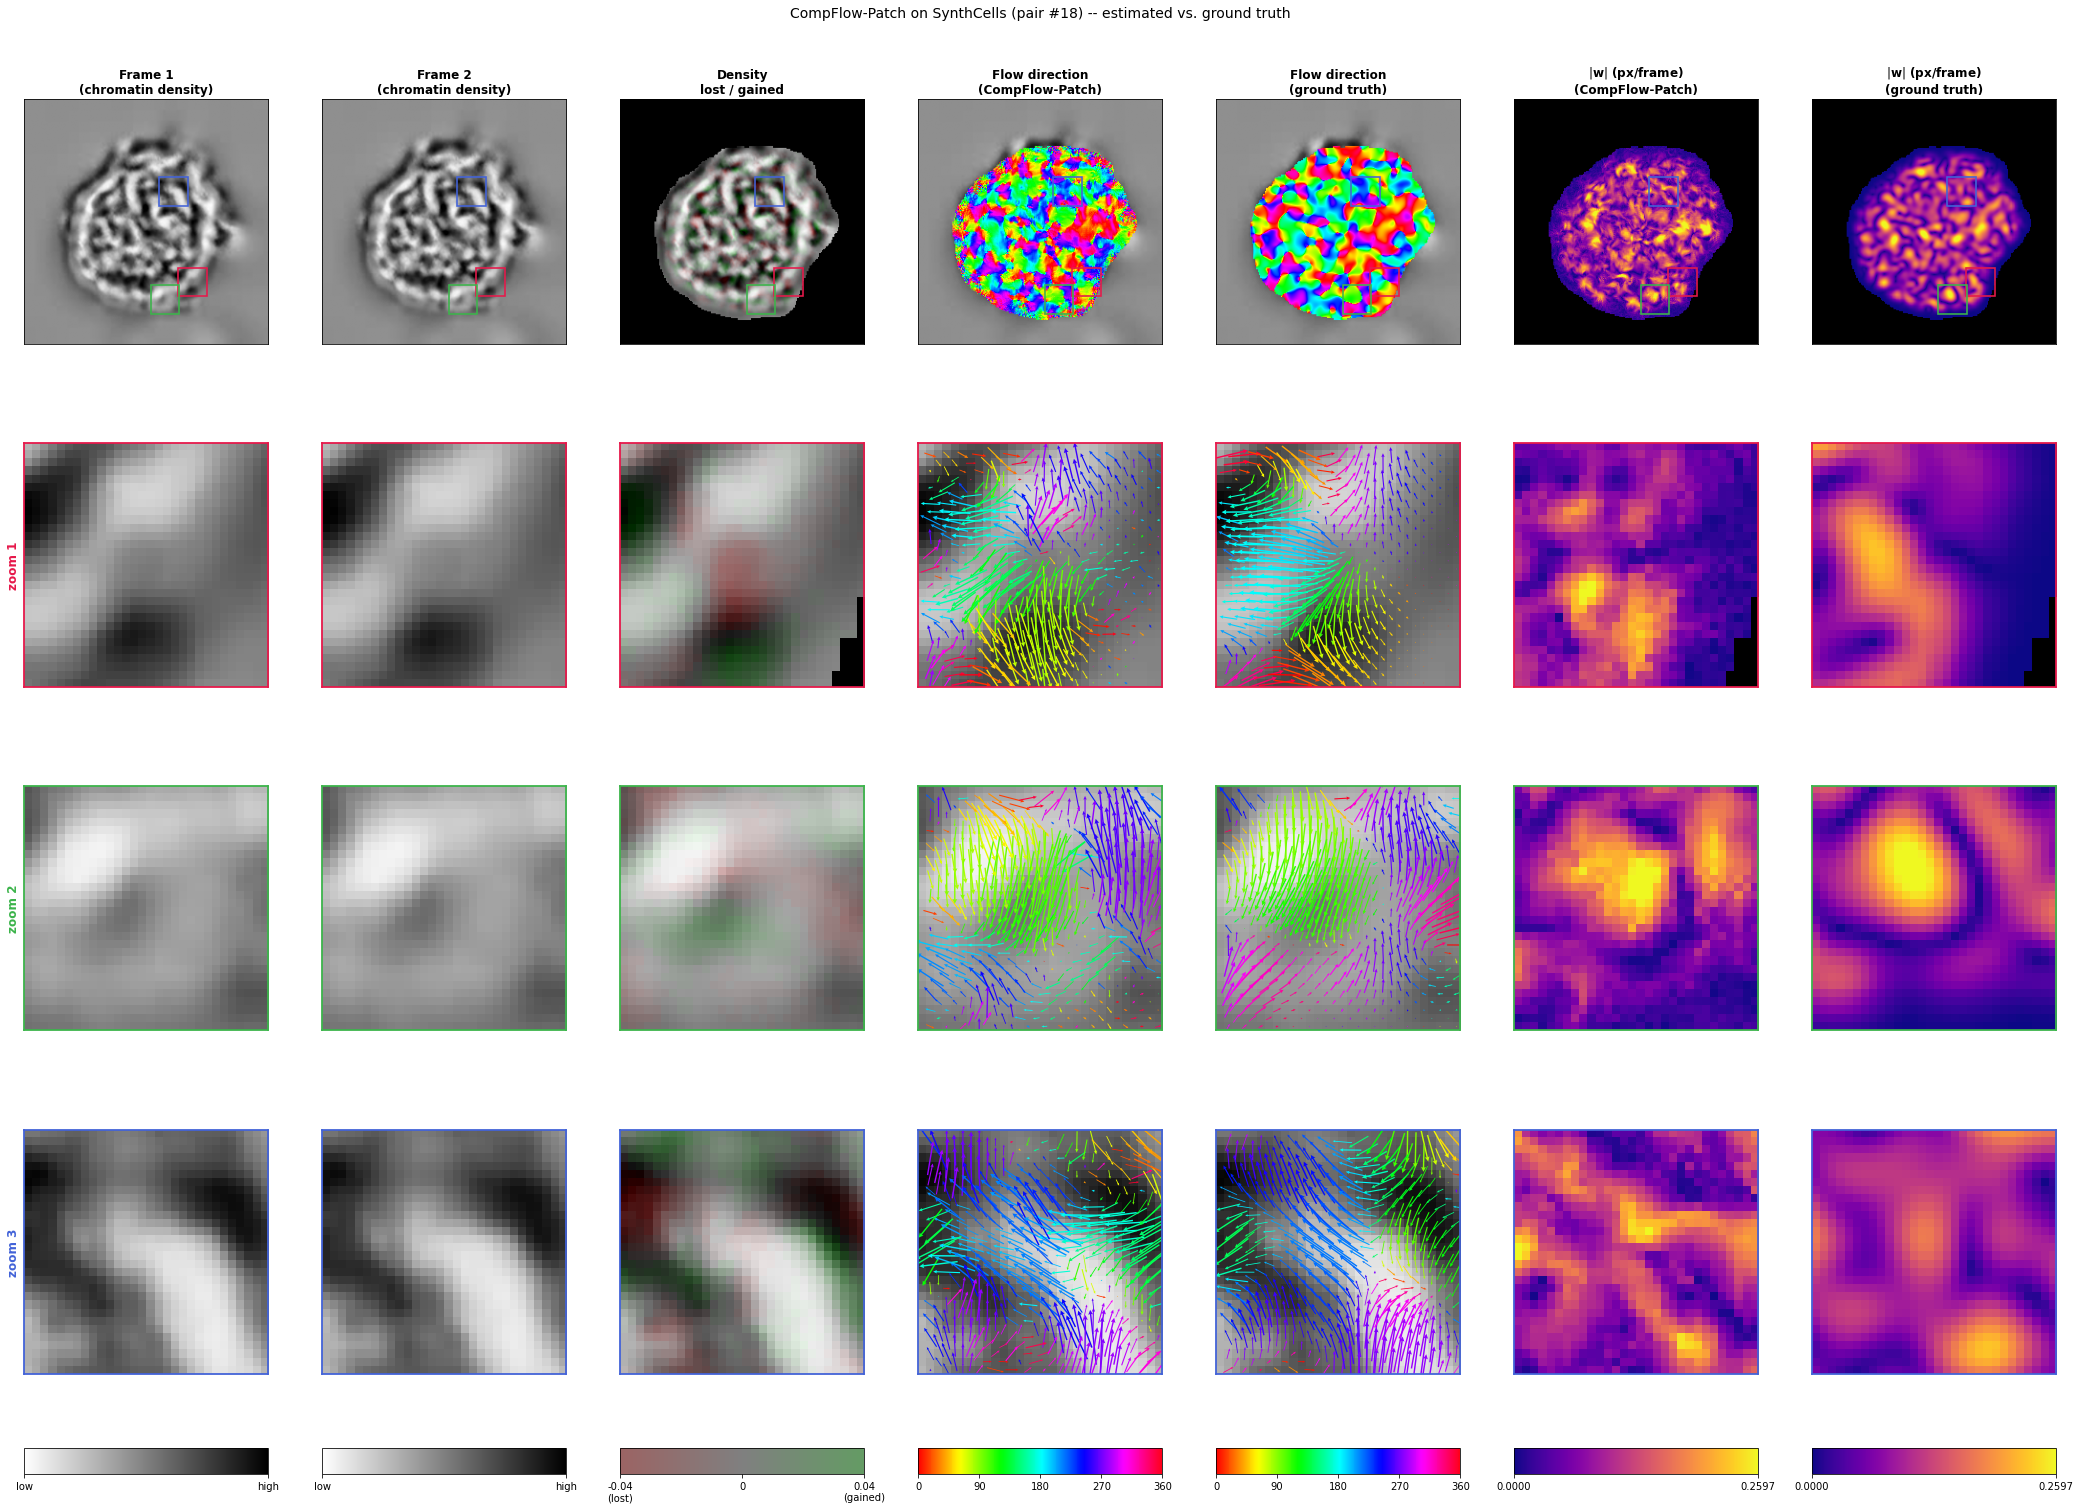

In [7]:
plot_motion_map_with_gt(
    img1, img2, mask, u_gh, v_gh, gt["u_gt"], gt["v_gt"],
    zoom_regions, ZOOM_COLORS, ZOOM,
    suptitle=f"CompFlow-Patch on SynthCells (pair #{PAIR_IDX}) -- estimated vs. ground truth",
)

## 5. Cross-check against `paper 1/main` -- does it give the same result?

Same frame pair, same method (`CompFlow-Patch` = `DF_WEDC_LK`), same SynthCells-calibrated parameters, same random seed -- but now using the **original** implementation the paper's `main.py` actually runs (`paper 1/Methods/density_flow_wedc_ventana.py`), not the GitHub copy.

One wrinkle: both the GitHub repo and `paper 1/Methods/` ship their own file named `common.py` (same purpose -- density construction -- different parameter-name convention, English vs. Spanish). Python only keeps one module named `common` cached at a time, and the GitHub one is already loaded from the cells above, so we drop it from the cache and put `paper 1/Methods` first on `sys.path` before importing the original module -- this only affects what `density_flow_wedc_ventana` (imported fresh right after) picks up; `compflow_patch` from the GitHub repo already finished importing earlier and is unaffected.

In [8]:
import importlib

_PAPER1 = os.path.dirname(os.getcwd())  # .../paper 1
del sys.modules["common"]               # drop the GitHub repo's cached common.py
sys.path.insert(0, os.path.join(_PAPER1, "Methods"))
sys.path.insert(0, os.path.join(_PAPER1, "main", "datasets"))

import density_flow_wedc_ventana as main_compflow_patch   # the ORIGINAL implementation
import synth_cells                                         # the ORIGINAL (Spanish-keyed) calibrated params

params_main = dict(synth_cells.PARAMS["DF_WEDC_LK"])
print("paper 1/main parameters:", params_main)

torch.manual_seed(0)
state_main = main_compflow_patch.prepare(params_main, device=DEVICE)
u_main, v_main, _ = main_compflow_patch.run(state_main, params_main, img1, img2, device=DEVICE)

paper 1/main parameters: {'desenfoque': 1, 'flujo_cromatina': True, 'iteraciones': 100, 'tasa_aprendizaje': 0.05, 'window_size': 5}


GitHub   |w| mean (mask) = 0.086196
main     |w| mean (mask) = 0.086196
max|du| = 1.08e-03   max|dv| = 1.65e-03  (floating-point/CUDA noise floor, not a real difference)


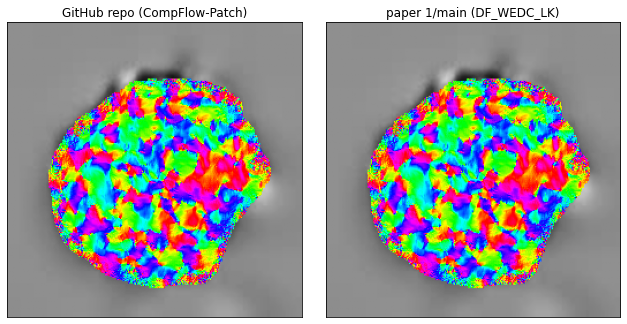

In [9]:
max_du = np.abs(u_gh - u_main).max()
max_dv = np.abs(v_gh - v_main).max()
print(f"GitHub   |w| mean (mask) = {np.hypot(u_gh, v_gh)[mask > 0].mean():.6f}")
print(f"main     |w| mean (mask) = {np.hypot(u_main, v_main)[mask > 0].mean():.6f}")
print(f"max|du| = {max_du:.2e}   max|dv| = {max_dv:.2e}  (floating-point/CUDA noise floor, not a real difference)")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, u, v, title in ((axes[0], u_gh, v_gh, "GitHub repo (CompFlow-Patch)"),
                        (axes[1], u_main, v_main, "paper 1/main (DF_WEDC_LK)")):
    rgb, visible = dense_direction_map(u, v, mask, img1, threshold=0.0)
    ax.imshow(img1, cmap="gray", vmin=0, vmax=255)
    ax.imshow(np.concatenate([rgb, visible[..., None].astype(np.float32)], axis=-1))
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

Both panels should look identical, and `max|du|`/`max|dv|` should be tiny (`~1e-3` or smaller on values of order `1`) -- confirming the GitHub repo reproduces the original implementation exactly, modulo ordinary floating-point noise.